## Procedure:

1. follow the setup in the image.
![Example Setup](setup_tanh.png)

2. setup the loadcell and wrap the string a
3. Modify the configuration file to use tanh
    
    dict(
    component=VirtualComponent(
        spring=TanhSpring(50.0,5.0),
        damper=LinearDamper(5.0),
        s_param=1.0,
        name="lin_seg3",
    ),follow
    goal=go_x_y,

4. Execute python3 Sequential_jump_tests.py


# Tanh vs Linear Spring — Saturation Comparison

Both runs use `Sequential_jump_tests.py`: the reference jumps to progressively
deeper x targets (−5cm … −50cm), holds at each, then snaps back to x=0 with a
high return stiffness (k=200).

- **tanh_k50.npz** — `TanhSpring(50.0, max_force=4.0)`
- **linear_k50.npz** — `LinearSpring(50.0)`

**Goal:** show that the tanh spring's virtual force **saturates at F_max = 4.0 N**,
while the linear spring force grows **without bound**.

> The snap-back phases (k = 200) are removed. We sequentially extract the hold
> windows where the *test* stiffness is active (k ≠ 200) and compare per target.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

F_MAX = 4.0          # tanh saturation limit [N]
K_RETURN = 200.0     # snap-back stiffness to exclude
SS_FRAC = 0.40       # fraction (tail) of each window used for steady-state

files = {
    "Tanh (Fmax=4.0)": "tanh_k50.npz",
    "Linear":          "linear_k50.npz",
}
colors = {"Tanh (Fmax=4.0)": "tab:red", "Linear": "tab:blue"}


def extract_windows(fn):
    """Return per-target hold windows, excluding the k=200 snap-back phases."""
    d = np.load(fn, allow_pickle=True)
    t      = d["t"]
    k      = d["k_params"][:, 0]
    goalx  = d["goal"][:, 0, 0]
    posx   = d["comp_pos"][:, 0, 0]
    fx     = d["f_virtual"][:, 0]
    fmag   = np.linalg.norm(d["f_virtual"], axis=1)

    # mask = test phases (anything that is NOT the snap-back stiffness)
    mask = ~np.isclose(k, K_RETURN)
    edges = np.diff(mask.astype(int))
    starts = np.where(edges == 1)[0] + 1
    ends   = np.where(edges == -1)[0] + 1
    if mask[0]:  starts = np.r_[0, starts]
    if mask[-1]: ends   = np.r_[ends, len(mask)]

    wins = []
    for s, e in zip(starts, ends):
        if e - s < 10:
            continue
        target = round(np.median(goalx[s:e]) / 0.05) * 0.05   # snap to 5cm grid
        if abs(target) < 1e-6:
            continue
        tail = slice(s + int((1 - SS_FRAC) * (e - s)), e)
        wins.append(dict(
            target=target,
            t=t[s:e] - t[s],          # time since jump
            goalx=goalx[s:e],
            posx=posx[s:e],
            fx=fx[s:e],
            fmag=fmag[s:e],
            fx_ss=np.mean(fx[tail]),
            posx_ss=np.mean(posx[tail]),
            fmag_ss=np.mean(fmag[tail]),
        ))
    wins.sort(key=lambda w: -w["target"])   # -0.05 first ... -0.50 last
    return wins


data = {name: extract_windows(fn) for name, fn in files.items()}
for name, wins in data.items():
    print(f"{name}: {len(wins)} test windows  "
          f"(targets {wins[0]['target']:.2f} … {wins[-1]['target']:.2f} m)")


Tanh (Fmax=4.0): 10 test windows  (targets -0.05 … -0.50 m)
Linear: 10 test windows  (targets -0.05 … -0.50 m)


## 1. Force–displacement saturation curve

Steady-state virtual force **|Fx|** vs commanded displacement **|goal|**.
The tanh curve flattens at **F_max = 4.0 N**; the linear curve keeps climbing.

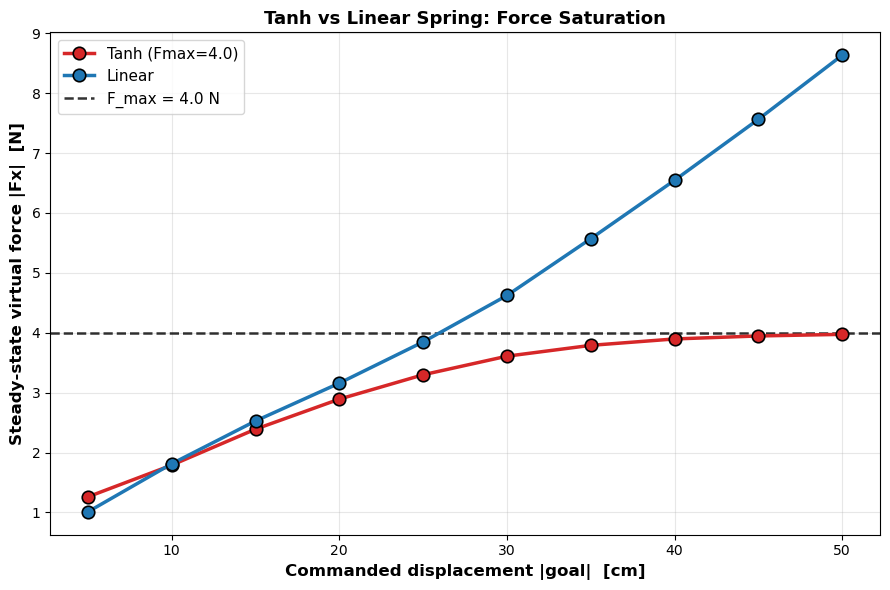

→ Tanh force asymptotes to F_max; Linear force is unbounded (F = k·Δx).


In [2]:
fig, ax = plt.subplots(figsize=(9, 6))

for name, wins in data.items():
    disp = np.array([abs(w["target"]) for w in wins])
    f_ss = np.array([abs(w["fx_ss"]) for w in wins])
    ax.plot(disp * 100, f_ss, "o-", color=colors[name], linewidth=2.5,
            markersize=9, markeredgecolor="black", markeredgewidth=1.2,
            label=name, zorder=3)

ax.axhline(F_MAX, color="black", linestyle="--", linewidth=1.8, alpha=0.8,
           label=f"F_max = {F_MAX:.1f} N", zorder=2)

ax.set_xlabel("Commanded displacement |goal|  [cm]", fontsize=12, fontweight="bold")
ax.set_ylabel("Steady-state virtual force |Fx|  [N]", fontsize=12, fontweight="bold")
ax.set_title("Tanh vs Linear Spring: Force Saturation", fontsize=13, fontweight="bold")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11, loc="upper left")
plt.tight_layout()
plt.show()

print("→ Tanh force asymptotes to F_max; Linear force is unbounded (F = k·Δx).")


## 2. Force transients per target

Each colored line is one displacement jump (time aligned to the jump instant).
**Left (tanh):** every curve flattens onto the F_max ceiling.
**Right (linear):** curves fan out — deeper targets reach ever larger forces.

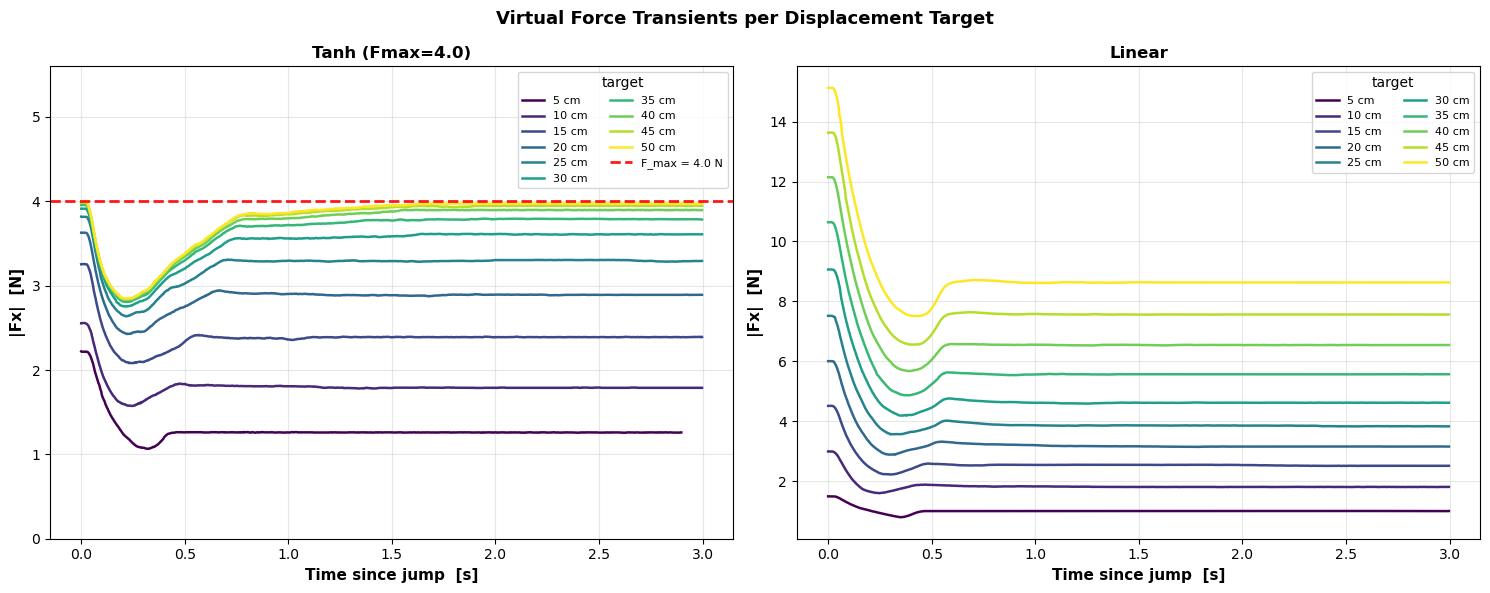

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=False)

for ax, (name, wins) in zip(axes, data.items()):
    cmap = plt.colormaps["viridis"]
    for i, w in enumerate(wins):
        c = cmap(i / max(1, len(wins) - 1))
        ax.plot(w["t"], np.abs(w["fx"]), color=c, linewidth=1.8,
                label=f"{abs(w['target'])*100:.0f} cm")
    if "Tanh" in name:
        ax.axhline(F_MAX, color="red", linestyle="--", linewidth=2,
                   alpha=0.9, label=f"F_max = {F_MAX:.1f} N")
    ax.set_xlabel("Time since jump  [s]", fontsize=11, fontweight="bold")
    ax.set_ylabel("|Fx|  [N]", fontsize=11, fontweight="bold")
    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, ncol=2, title="target")

axes[0].set_ylim(0, F_MAX * 1.4)   # tanh: zoom on the ceiling
fig.suptitle("Virtual Force Transients per Displacement Target",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## 3. Steady-state force per target (grouped bars)

Side-by-side steady-state |Fx|. The tanh bars clip at the F_max line; the linear
bars grow past it without limit.

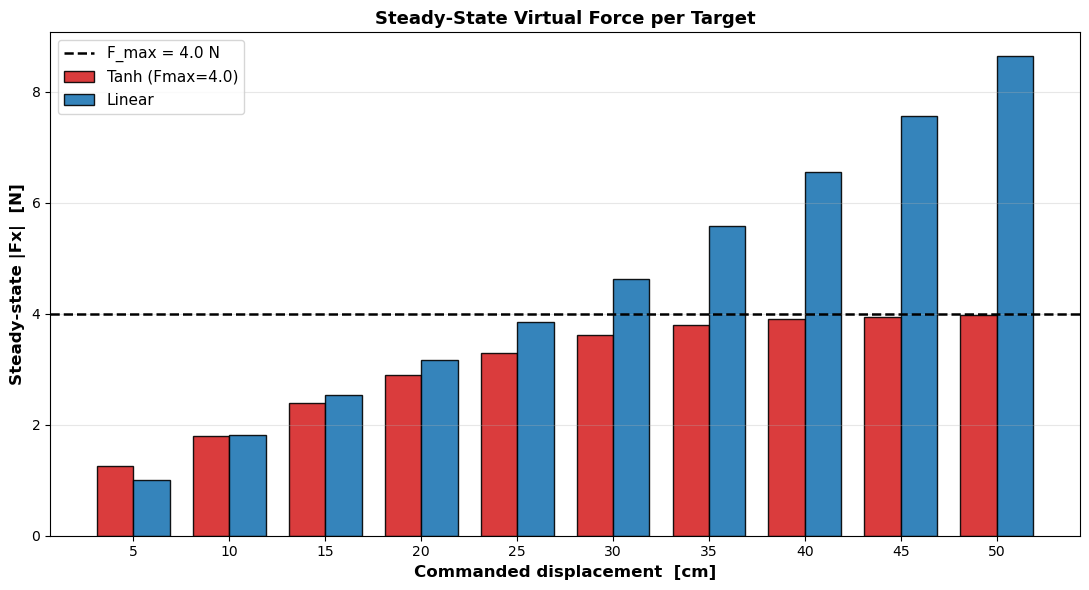

In [4]:
targets = sorted({abs(w["target"]) for w in data["Tanh (Fmax=4.0)"]})
x = np.arange(len(targets))
width = 0.38

fig, ax = plt.subplots(figsize=(11, 6))
for off, name in zip((-width/2, width/2), files):
    lut = {round(abs(w["target"]), 4): abs(w["fx_ss"]) for w in data[name]}
    vals = [lut.get(round(t, 4), np.nan) for t in targets]
    ax.bar(x + off, vals, width, color=colors[name], edgecolor="black",
           label=name, alpha=0.9)

ax.axhline(F_MAX, color="black", linestyle="--", linewidth=1.8,
           label=f"F_max = {F_MAX:.1f} N")
ax.set_xticks(x)
ax.set_xticklabels([f"{t*100:.0f}" for t in targets])
ax.set_xlabel("Commanded displacement  [cm]", fontsize=12, fontweight="bold")
ax.set_ylabel("Steady-state |Fx|  [N]", fontsize=12, fontweight="bold")
ax.set_title("Steady-State Virtual Force per Target", fontsize=13, fontweight="bold")
ax.grid(True, axis="y", alpha=0.3)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


## 4. Mechanical consequence — end-effector yield

Because the tanh force is capped, the arm **cannot be held as close to deep
targets**: its actual x plateaus while the linear arm keeps following. This is the
compliance/safety trade-off of saturating the virtual force.

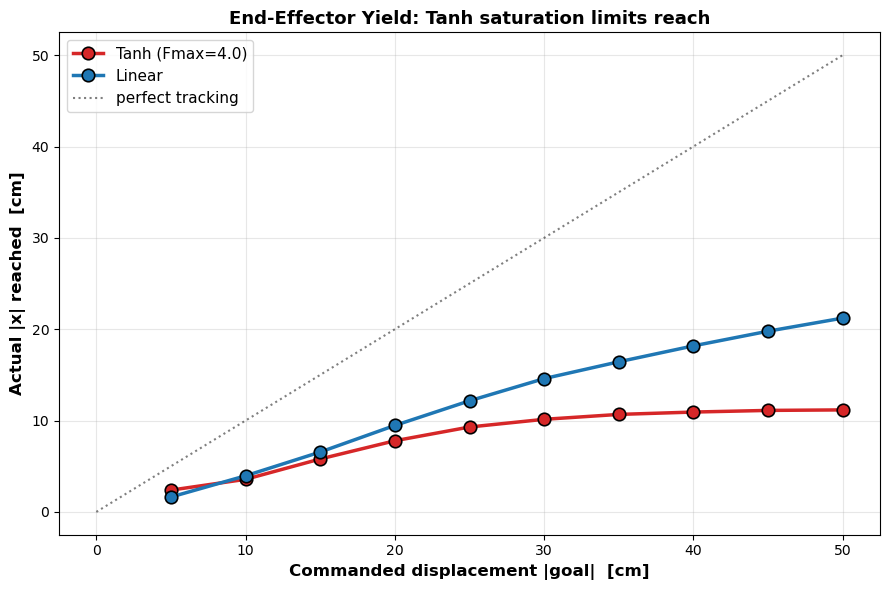

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))

for name, wins in data.items():
    disp = np.array([abs(w["target"]) for w in wins])
    pos  = np.array([abs(w["posx_ss"]) for w in wins])
    ax.plot(disp * 100, pos * 100, "o-", color=colors[name], linewidth=2.5,
            markersize=9, markeredgecolor="black", markeredgewidth=1.2, label=name)

ax.plot([0, max(disp)*100], [0, max(disp)*100], "k:", alpha=0.5,
        label="perfect tracking")
ax.set_xlabel("Commanded displacement |goal|  [cm]", fontsize=12, fontweight="bold")
ax.set_ylabel("Actual |x| reached  [cm]", fontsize=12, fontweight="bold")
ax.set_title("End-Effector Yield: Tanh saturation limits reach",
             fontsize=13, fontweight="bold")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11, loc="upper left")
plt.tight_layout()
plt.show()


## 5. Summary table

In [6]:
print(f"{'Target':>8} | {'Tanh |Fx|':>10} | {'Linear |Fx|':>12} | {'Lin/Tanh':>9}")
print("-" * 50)
tanh = {round(abs(w['target']),4): abs(w['fx_ss']) for w in data['Tanh (Fmax=4.0)']}
lin  = {round(abs(w['target']),4): abs(w['fx_ss']) for w in data['Linear']}
for t in sorted(tanh):
    ft, fl = tanh[t], lin.get(t, np.nan)
    ratio = fl / ft if ft else np.nan
    print(f"{t*100:6.0f}cm | {ft:9.2f}N | {fl:11.2f}N | {ratio:8.2f}x")
print("-" * 50)
print(f"Tanh saturates near F_max = {F_MAX:.1f} N; Linear grows linearly with k·Δx.")


  Target |  Tanh |Fx| |  Linear |Fx| |  Lin/Tanh
--------------------------------------------------
     5cm |      1.26N |        1.01N |     0.80x
    10cm |      1.79N |        1.81N |     1.01x
    15cm |      2.39N |        2.53N |     1.06x
    20cm |      2.89N |        3.16N |     1.09x
    25cm |      3.30N |        3.85N |     1.17x
    30cm |      3.61N |        4.62N |     1.28x
    35cm |      3.79N |        5.57N |     1.47x
    40cm |      3.90N |        6.55N |     1.68x
    45cm |      3.95N |        7.57N |     1.92x
    50cm |      3.97N |        8.63N |     2.17x
--------------------------------------------------
Tanh saturates near F_max = 4.0 N; Linear grows linearly with k·Δx.
